# 02 - Prediction Design and Feature Engineering

**Prediction point.** For horizon *h*, a prediction is made for every product listed in an edition at `WeeksOut = -h`, using only weekly rows with `WeeksOut <= -h` and outcomes of earlier editions. The primary horizon is **13 weeks** (the point at which the live edition 94 was extracted, and early enough for clearance, supplier and stock decisions). Horizons 24, 6 and 1 are compared in notebook 03.

Feature logic: `src/product_discontinuation/features.py` (`build_features`). The same function is used for training, the Streamlit app and monitoring.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from product_discontinuation import config

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 110})

In [2]:
from product_discontinuation import data, features as F

weekly = data.load_dataset()
history = F.edition_history(weekly)
feats = F.build_features(weekly, config.PRIMARY_HORIZON, history=history)
print(feats.shape)
feats.head()

(166856, 26)


,CatEdition,ProductKey,log_price,price_missing,log_actuals,log_forecast,forecast_to_actual,zero_actuals,weeks_in_edition,forecast_volatility,actuals_volatility,actuals_trend,forecast_trend,status_ro,status_ro_share,status_changes,in_previous_edition,previous_discontinued,prior_editions,Supplier,HierarchyLevel1,HierarchyLevel2,DIorDOM,Seasonal,SpringSummer,DiscontinuedTF
0,90,8108,3.496204,0,3.765053,3.187592,-0.577462,0,12,0.208514,0.133353,-0.149467,-0.279955,0,0.916667,1.0,1.0,0.0,1.0,78589,67967,32668,DOM,0,0,0
1,91,8108,3.177637,0,2.639057,3.533102,0.894045,0,12,0.097530,0.137330,-0.085522,0.008479,1,1.000000,0.0,1.0,0.0,2.0,78589,67967,32668,DOM,0,1,0
2,92,8108,3.177637,0,1.734483,1.999315,0.264832,0,12,0.057581,0.107636,-0.057276,-0.094645,0,0.916667,1.0,1.0,0.0,3.0,78589,67967,32668,DOM,0,0,1
3,89,71280,3.806440,0,4.001242,5.475819,1.474577,0,12,1.615062,0.373108,0.638266,-0.046581,0,0.000000,0.0,0.0,NaN,0.0,65093,10159,57189,DI,0,1,0
4,90,71280,3.688629,0,4.780517,4.636960,-0.143558,0,12,0.086988,0.210647,-0.049794,0.170385,0,0.166667,1.0,1.0,0.0,1.0,65093,10159,57189,DI,0,0,0


## Feature catalogue
| Feature | Definition (as of week -h) | Rationale |
|---|---|---|
| `log_actuals` | log1p average weekly demand since previous refresh | Low sellers are delisted |
| `log_forecast` | log1p planners' forecast for remaining weeks | Expected future demand |
| `forecast_to_actual` | log forecast - log actuals | Forecast optimism / pessimism |
| `actuals_trend`, `forecast_trend` | change in log value over the last 4 weeks | Momentum (not available at h=24) |
| `actuals_volatility`, `forecast_volatility` | std of log values over observed weeks | Demand instability (not at h=24) |
| `log_price`, `price_missing` | log selling price; 0 treated as missing | Price point |
| `zero_actuals` | no recorded sales | Dormant products |
| `weeks_in_edition` | weeks since product first appeared in this edition | Late additions behave differently |
| `in_previous_edition`, `previous_discontinued`, `prior_editions` | presence/outcome in earlier editions | Product tenure and past decisions (known before this edition starts) |
| Supplier, HierarchyLevel1/2, DIorDOM, Seasonal, SpringSummer | product metadata | Category-level delisting patterns |

Excluded: `Status` features (benchmark only), ProductKey/CatEdition (identifiers), any count of total observations in the edition, any row after week -h.

In [3]:
numeric, categorical, binary = F.feature_columns(config.PRIMARY_HORIZON)
print("numeric:", numeric); print("categorical:", categorical); print("binary:", binary)
feats[numeric].describe().T.round(3)

numeric: ['log_price', 'log_actuals', 'log_forecast', 'forecast_to_actual', 'weeks_in_edition', 'in_previous_edition', 'previous_discontinued', 'prior_editions', 'forecast_volatility', 'actuals_volatility', 'actuals_trend', 'forecast_trend']
categorical: ['Supplier', 'HierarchyLevel1', 'HierarchyLevel2', 'DIorDOM']
binary: ['Seasonal', 'SpringSummer', 'zero_actuals', 'price_missing']


,count,mean,std,min,25%,50%,75%,max
log_price,166288.0,3.599,1.129,-4.605,2.772,3.401,4.248,8.517
log_actuals,166856.0,3.432,1.671,0.000,2.311,3.584,4.636,9.468
log_forecast,166856.0,3.790,1.559,0.073,2.743,3.860,4.872,10.208
forecast_to_actual,166856.0,0.358,0.953,-7.595,-0.110,0.174,0.632,10.124
weeks_in_edition,166856.0,11.621,1.567,1.000,12.000,12.000,12.000,12.000
in_previous_edition,144170.0,0.720,0.449,0.000,0.000,1.000,1.000,1.000
previous_discontinued,103867.0,0.095,0.293,0.000,0.000,0.000,0.000,1.000
prior_editions,144170.0,1.655,1.595,0.000,0.000,1.000,3.000,6.000
forecast_volatility,166196.0,0.237,0.265,0.000,0.089,0.154,0.279,4.166
actuals_volatility,166196.0,0.200,0.249,0.000,0.073,0.130,0.228,4.435


In [4]:
feats[F.all_feature_columns(config.PRIMARY_HORIZON)].isna().mean().loc[lambda s: s > 0].round(3)

log_price                0.003
in_previous_edition      0.136
previous_discontinued    0.378
prior_editions           0.136
forecast_volatility      0.004
actuals_volatility       0.004
actuals_trend            0.019
forecast_trend           0.019
dtype: float64

Missing values are structural: history is undefined for edition 88 (first edition in the data - it is therefore used only as history, not as a training row), `previous_discontinued` is undefined for products new to the range, and trends need a week -h-4 observation. They are median-imputed inside the pipeline (fitted on training folds only).

## Leakage check: altering future rows must not change features

In [5]:
tampered = weekly.copy()
future = tampered.WeeksOut > -config.PRIMARY_HORIZON
tampered.loc[future, ["ActualsPerWeek", "ForecastPerWeek"]] *= 100
tampered.loc[future, "Status"] = "RO"
rebuilt = F.build_features(tampered, config.PRIMARY_HORIZON, history=history)
pd.testing.assert_frame_equal(feats, rebuilt)
print("Identical features - no information after the prediction week is used.")

Identical features - no information after the prediction week is used.


## Univariate signal per edition (ROC-AUC of each raw feature)

In [6]:
from sklearn.metrics import roc_auc_score
labelled = feats[feats.CatEdition.between(config.MODEL_FIRST_EDITION, config.TEST_EDITION)]
rows = {}
for col in numeric + ["status_ro"]:
    rows[col] = {e: roc_auc_score(g.DiscontinuedTF[g[col].notna()], g[col].dropna())
                 for e, g in labelled.groupby("CatEdition")}
pd.DataFrame(rows).T.round(3)

,89,90,91,92,93
log_price,0.517,0.511,0.525,0.515,0.472
log_actuals,0.290,0.341,0.309,0.331,0.230
log_forecast,0.310,0.328,0.328,0.314,0.254
forecast_to_actual,0.532,0.500,0.545,0.517,0.600
weeks_in_edition,0.472,0.482,0.467,0.489,0.397
in_previous_edition,0.465,0.517,0.468,0.507,0.420
previous_discontinued,0.587,0.591,0.593,0.574,0.577
prior_editions,0.465,0.488,0.440,0.458,0.400
forecast_volatility,0.610,0.572,0.593,0.576,0.552
actuals_volatility,0.627,0.562,0.611,0.558,0.485


Values below 0.5 indicate a negative relationship (e.g. higher sales -> less likely to be discontinued). The signal of individual demand features varies noticeably between editions; edition 93 is more separable than 91-92, which matters when interpreting a single test edition. `status_ro` is far stronger than any demand feature, consistent with it encoding the decision itself.

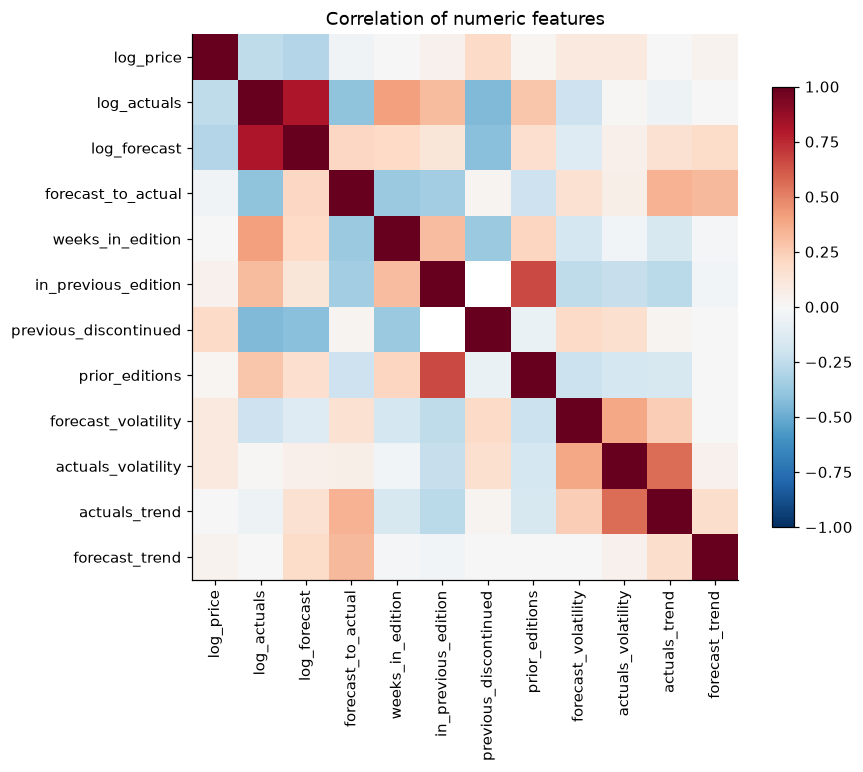

In [7]:
corr = labelled[numeric].corr()
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90); ax.set_yticks(range(len(corr)), corr.columns)
ax.grid(False); fig.colorbar(im, ax=ax, shrink=0.8); ax.set_title("Correlation of numeric features")
plt.show()

`log_actuals` and `log_forecast` are strongly correlated (forecasts are anchored on sales); `forecast_to_actual` keeps the information in their difference. Logistic regression uses L2 regularisation, which handles the collinearity.

## Preprocessing pipeline

In [8]:
from product_discontinuation.modelling import make_preprocessor
pre = make_preprocessor(config.PRIMARY_HORIZON)
train = labelled[labelled.CatEdition < config.TEST_EDITION]
Xt = pre.fit_transform(train[F.all_feature_columns(config.PRIMARY_HORIZON)])
print("Encoded training matrix:", Xt.shape)
pre

Encoded training matrix: (89286, 605)


ColumnTransformer(transformers=[('numeric',
                                 Pipeline(steps=[('impute',
                                                  SimpleImputer(strategy='median')),
                                                 ('scale', StandardScaler())]),
                                 ['log_price', 'log_actuals', 'log_forecast',
                                  'forecast_to_actual', 'weeks_in_edition',
                                  'in_previous_edition',
                                  'previous_discontinued', 'prior_editions',
                                  'forecast_volatility', 'actuals_volatility',
                                  'actuals_trend', 'forecast_tren...
                                 Pipeline(steps=[('impute',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encode',
                                                  OneHotEncoder(handle_unknown='infrequent_if_exist',
                                                                min_frequency=50,
                                                                sparse_output=False))]),
                                 ['Supplier', 'HierarchyLevel1',
                                  'HierarchyLevel2', 'DIorDOM']),
                                ('binary',
                                 SimpleImputer(strategy='most_frequent'),
                                 ['Seasonal', 'SpringSummer', 'zero_actuals',
                                  'price_missing'])],
                  verbose_feature_names_out=False)

Numeric: median imputation + standardisation. Categorical: most-frequent imputation + one-hot encoding with `min_frequency=50` (rare suppliers/categories are grouped as *infrequent*; unseen ones at inference map to that group). Binary: most-frequent imputation. The transformer is part of the model pipeline, so it is fitted only on training folds during CV and persisted with the model.

## Horizon coverage

In [9]:
sizes = {h: len(F.build_features(weekly, h, history=history).query("CatEdition >= @config.MODEL_FIRST_EDITION and CatEdition <= @config.TEST_EDITION")) for h in config.HORIZONS}
sizes

{24: 109661, 13: 116069, 6: 116653, 1: 115321}